# Character CNN Error Analysis and t-SNE

COSC 50523 — Deep Minds
Leiton Peterson

Adapted from the team's week3/C3_error_analysis_tsne.py script.

This notebook loads the saved default character CNN and examines
its mistakes on the validation split. It compares characteristics
of correctly and incorrectly classified URLs and visualizes a
sample of the model's learned representations using t-SNE.

The model is not retrained, and the test split is not evaluated.

Labels:
- 0 = legitimate
- 1 = phishing

In [1]:
import sys
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')

DATA_DIR = Path('/content/drive/MyDrive/DeepMinds')
sys.path.insert(0, str(DATA_DIR))

FIG_DIR = DATA_DIR / 'figures'
FIG_DIR.mkdir(exist_ok=True)

required_files = [
    'master_with_splits.csv',
    'project_utils.py',
    'torch_models.py',
    'char_cnn_default.pt',
]

for filename in required_files:
    path = DATA_DIR / filename
    assert path.is_file(), f"Missing file: {path}"
    print("Found:", filename)

Mounted at /content/drive
Found: master_with_splits.csv
Found: project_utils.py
Found: torch_models.py
Found: char_cnn_default.pt


In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from project_utils import load_master, encode_urls, strip_prefix
from torch_models import (
    CharCNN,
    predict_proba,
    hidden_features,
    DEVICE,
)

# Load the saved architecture settings, vocabulary, and weights.
ckpt = torch.load(
    DATA_DIR / 'char_cnn_default.pt',
    map_location='cpu',
    weights_only=True,
)

cfg = ckpt['config']
vocab = ckpt['vocab']

model = CharCNN(
    vocab_size=len(vocab) + 2,
    embed_dim=cfg['embed_dim'],
    filters=cfg['filters'],
    kernel_sizes=cfg['kernel_sizes'],
    dropout=cfg['dropout'],
    hidden=cfg['hidden'],
    use_conv=cfg['use_conv'],
).to(DEVICE)

model.load_state_dict(ckpt['state_dict'])
model.eval()

# Select validation rows only.
df = load_master(DATA_DIR)
val = df[df['split'] == 'val'].copy()

# Use the same URL processing and vocabulary as the saved model.
urls = val['URL'].tolist()
if cfg.get('strip_prefix', False):
    urls = [strip_prefix(url) for url in urls]

X_val = encode_urls(urls, vocab, cfg['max_len'])

val['p_phishing'] = predict_proba(
    model,
    X_val,
    x_dtype=torch.long,
)

threshold = ckpt.get('threshold', 0.5)
val['pred'] = (val['p_phishing'] >= threshold).astype(int)

print("Device:", DEVICE)
print("Validation examples:", len(val))
print("Prediction threshold:", threshold)
print("Saved CNN loaded and validation predictions generated.")

Device: cpu
Validation examples: 35369
Prediction threshold: 0.5
Saved CNN loaded and validation predictions generated.


## Validation mistakes

A false negative is a phishing URL classified as legitimate.
A false positive is a legitimate URL classified as phishing.

We inspect the model's most confident mistakes to identify
possible patterns and limitations.

In [3]:
# Phishing URLs incorrectly predicted as legitimate.
missed = val[
    (val['label'] == 1) & (val['pred'] == 0)
].sort_values('p_phishing')

# Legitimate URLs incorrectly predicted as phishing.
false_alarm = val[
    (val['label'] == 0) & (val['pred'] == 1)
].sort_values('p_phishing', ascending=False)

print("Missed phishing URLs:", len(missed))
print("False alarms:", len(false_alarm))

# Print as plain text rather than clickable links.
print("\nMost confident missed phishing examples:")
print(
    missed[['URL', 'p_phishing']]
    .head(15)
    .to_string(index=False)
)

print("\nLegitimate URLs flagged as phishing:")
print(
    false_alarm[['URL', 'p_phishing']]
    .head(10)
    .to_string(index=False)
)

Missed phishing URLs: 66
False alarms: 1

Most confident missed phishing examples:
                             URL  p_phishing
      https://www.hoststudio.org    0.000945
        https://www.yihaonan.com    0.000998
            https://www.cuag.fit    0.001070
     https://www.direlandgun.com    0.001155
    https://www.escuelahalal.com    0.001346
    https://www.gassopereyra.com    0.001438
https://www.inforegihtofuses.com    0.001485
         https://www.tinyurl.com    0.001500
         https://www.faewood.com    0.001549
           https://www.pajani.ir    0.001634
    https://www.iplayukulele.com    0.001749
      https://www.officested.com    0.001866
   https://www.ownagedomains.com    0.001893
       https://www.colis-dhl.com    0.001924
              https://www.cfg.me    0.002055

Legitimate URLs flagged as phishing:
                     URL  p_phishing
https://www.365chess.com     0.96842


## Characteristics of validation errors

Compare URL characteristics across the full validation classes and
the misclassified examples. These comparisons are descriptive and
do not establish why the model made a particular prediction.

There is only one false positive, so its characteristics should not
be generalized to other legitimate websites.

In [4]:
def describe_urls(rows):
    urls = rows['URL']

    return pd.Series({
        'Count': len(rows),
        'Mean URL length': urls.str.len().mean(),
        'Uses HTTPS (%)': urls.str.lower()
            .str.startswith('https://').mean() * 100,
        'Contains www. (%)': urls.str.lower()
            .str.contains('www.', regex=False).mean() * 100,
        'Mean subdomain count': rows['NoOfSubDomain'].mean(),
        'Longer than model limit (%)': (
            urls.str.len() > cfg['max_len']
        ).mean() * 100,
    })

error_summary = pd.DataFrame({
    'All phishing': describe_urls(val[val['label'] == 1]),
    'Missed phishing': describe_urls(missed),
    'All legitimate': describe_urls(val[val['label'] == 0]),
    'False alarms': describe_urls(false_alarm),
})

display(error_summary.round(2))

# Save analysis outputs to shared Drive.
error_summary.to_csv(DATA_DIR / 'cnn_error_summary.csv')
missed.to_csv(DATA_DIR / 'cnn_missed_phishing.csv', index=False)
false_alarm.to_csv(DATA_DIR / 'cnn_false_alarms.csv', index=False)

print("Saved the summary and error examples to shared Drive.")

,All phishing,Missed phishing,All legitimate,False alarms
Count,15142.00,66.00,20227.00,1.0
Mean URL length,45.97,29.03,27.19,24.0
Uses HTTPS (%),48.96,100.00,100.00,100.0
Contains www. (%),41.69,100.00,100.00,100.0
Mean subdomain count,1.18,1.32,1.16,1.0
Longer than model limit (%),1.35,0.00,0.00,0.0


Saved the summary and error examples to shared Drive.


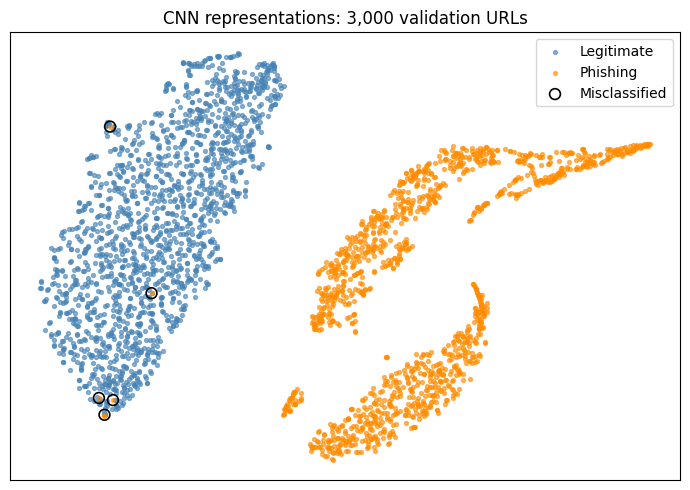

Misclassified examples in this sample: 5
Saved: /content/drive/MyDrive/DeepMinds/figures/tsne_cnn.png


In [5]:
from sklearn.manifold import TSNE

# Use the same reproducible sample size as the team's script.
sample = val.sample(n=3000, random_state=42)

sample_urls = sample['URL'].tolist()
if cfg.get('strip_prefix', False):
    sample_urls = [strip_prefix(url) for url in sample_urls]

sample_ids = encode_urls(sample_urls, vocab, cfg['max_len'])

# Extract the representations learned by the CNN.
Z = hidden_features(model, sample_ids, x_dtype=torch.long)

# Reduce those representations to two dimensions for visualization.
xy = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    init='pca',
).fit_transform(Z)

fig, ax = plt.subplots(figsize=(7, 5))

for label, color, name in [
    (0, 'steelblue', 'Legitimate'),
    (1, 'darkorange', 'Phishing'),
]:
    mask = sample['label'].to_numpy() == label
    ax.scatter(
        xy[mask, 0], xy[mask, 1],
        s=8, alpha=0.6, color=color, label=name,
    )

wrong = (sample['pred'] != sample['label']).to_numpy()
ax.scatter(
    xy[wrong, 0], xy[wrong, 1],
    s=60, facecolors='none', edgecolors='black',
    linewidths=1.2, label='Misclassified',
)

ax.set_title('CNN representations: 3,000 validation URLs')
ax.set_xticks([])
ax.set_yticks([])
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / 'tsne_cnn.png', dpi=200)
plt.show()

print("Misclassified examples in this sample:", int(wrong.sum()))
print("Saved:", FIG_DIR / 'tsne_cnn.png')

## Findings and limitations

The saved CNN reproduced 66 missed phishing URLs and 1 false alarm
on 35,369 validation examples.

Missed phishing URLs were shorter on average than phishing URLs
overall (29.03 versus 45.97 characters). All 66 misses used HTTPS
and contained "www.", characteristics also present in every legitimate
URL in this validation split. This pattern suggests a possible dataset
shortcut worth investigating, but does not establish which features
caused the model's errors.

None of the missed phishing URLs exceeded the 200-character input
limit, so truncation does not explain these misses. Only one false
positive was observed, which is insufficient for general conclusions
about false alarms.

The t-SNE visualization of 3,000 sampled validation URLs shows largely
separated class regions, with five misclassified examples appearing
within the predominantly legitimate region. This is an exploratory
projection of learned representations, not an additional performance
metric or evidence of reliable real-world detection.

No model retraining or test-set evaluation was performed.

This notebook follows the team's C3_error_analysis_tsne.py script.